# ClearBank — Análise Financeira com Python
**Thaís Sgalbiero** · Análise de Dados e Inteligência de Negócios com IA

## Antes de executar
O arquivo `transacoes.csv` foi preparado previamente com dados **inteiramente fictícios**: 15 registros válidos em janeiro, fevereiro e março de 2026, 10 linhas inválidas e 1 duplicata. Duas transações superam R$ 10.000,00; outra é exatamente igual ao limite.

**Local:** mantenha os arquivos na mesma pasta, instale `requirements.txt` e execute todas as células em ordem.
**Colab:** abra este notebook e envie `transacoes.csv`, `analise_nativa.py` e `analise_pandas.py` pelo painel Arquivos antes de executar. Pandas e matplotlib já estão disponíveis no Colab.

A parte obrigatória usa apenas a biblioteca padrão. As duas últimas etapas são extras.

## Decisões de análise
- IDs são inteiros não negativos; a primeira ocorrência **válida** prevalece. Duplicatas entram no total de inválidas e são também identificadas separadamente.
- Data exige formato exato e existência no calendário. Valores não finitos são rejeitados.
- A conversão para `float` é testada conforme o enunciado; os cálculos monetários usam `Decimal` para evitar acúmulo de erros binários. Arredondamento a centavos ocorre na saída.
- Alertas indicam apenas valores acima do limite, sem concluir fraude. Empates de maior/menor valor preservam a primeira transação.
- Dias decorridos usam a data de execução. Datas futuras, se fornecidas, terão diferença negativa.
- O trecho JSON fornecido no enunciado está incompleto; suas chaves visíveis foram preservadas e complementadas com métricas, período e alertas.


## 1. Configuração

In [1]:
import csv
import json
import math
import re
from datetime import datetime, date
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

LIMITE_SUSPEITO = 10000.00
COLUNAS = ['id', 'data', 'cliente_id', 'tipo', 'valor', 'descricao', 'categoria']
print('Configuração pronta. Solução principal: apenas biblioteca padrão.')

Configuração pronta. Solução principal: apenas biblioteca padrão.


## 2. Leitura do CSV

In [2]:
def ler_transacoes(caminho='transacoes.csv'):
    """Retorna registros brutos; None indica erro de arquivo, não base vazia."""
    try:
        with open(caminho, encoding='utf-8-sig', newline='') as arquivo:
            leitor = csv.DictReader(arquivo)
            if leitor.fieldnames != COLUNAS:
                print('Cabeçalho inválido. Colunas esperadas:', ', '.join(COLUNAS))
                return None
            return list(leitor)
    except FileNotFoundError:
        print(f'Arquivo não encontrado: {caminho}. Coloque o CSV na pasta do notebook.')
        return None
    except (OSError, UnicodeError, csv.Error) as erro:
        print(f'Não foi possível ler o CSV: {erro}')
        return None

brutas = ler_transacoes()
assert brutas is not None and len(brutas) == 26
print(f'Teste de leitura OK: {len(brutas)} registros encontrados.')

Teste de leitura OK: 26 registros encontrados.


## 3. Validação e limpeza

In [3]:
def validar_transacao(linha):
    """Descarta erros silenciosamente; mantém descrição e categoria opcionais."""
    if set(linha) != set(COLUNAS) or any(v is None for v in linha.values()):
        return None
    registro = {chave: valor.strip() for chave, valor in linha.items()}
    if not re.fullmatch(r'[0-9]+', registro['id']) or not registro['cliente_id']:
        return None
    if registro['tipo'] not in ('credito', 'debito'):
        return None
    try:
        valor = float(registro['valor'])
    except (ValueError, OverflowError):
        return None
    if not math.isfinite(valor) or valor <= 0:
        return None
    try:
        data = datetime.strptime(registro['data'], '%Y-%m-%d')
    except ValueError:
        return None
    if not re.fullmatch(r'[0-9]{4}-[0-9]{2}-[0-9]{2}', registro['data']):
        return None
    registro.update(id=int(registro['id']), data=data,
                    valor=Decimal(registro['valor']), suspeita=valor > LIMITE_SUSPEITO)
    return registro


def limpar_transacoes(linhas):
    """Primeiro registro válido de cada ID prevalece; duplicatas são descartes."""
    validas, ids = [], set()
    invalidas = duplicadas = 0
    for linha in linhas:
        registro = validar_transacao(linha)
        if registro is None:
            invalidas += 1
        elif registro['id'] in ids:
            invalidas += 1
            duplicadas += 1
        else:
            ids.add(registro['id'])
            validas.append(registro)
    return validas, invalidas, duplicadas

validas, invalidas, duplicadas = limpar_transacoes(brutas)
assert (len(validas), invalidas, duplicadas) == (15, 11, 1)
print('Teste de limpeza OK: 15 válidas, 11 descartadas (incluindo 1 duplicata).')

Teste de limpeza OK: 15 válidas, 11 descartadas (incluindo 1 duplicata).


## 4. Datas, agrupamento e métricas

In [4]:
def numero(valor):
    """Arredonda a apresentação a centavos, mantendo Decimal nos cálculos."""
    return float(valor.quantize(Decimal('0.01'), rounding=ROUND_HALF_UP))


def serializar_transacao(transacao):
    return {**transacao, 'data': transacao['data'].strftime('%Y-%m-%d'),
            'valor': numero(transacao['valor'])}


def resumir_mes(transacoes):
    credito = sum((t['valor'] for t in transacoes if t['tipo'] == 'credito'), Decimal(0))
    debito = sum((t['valor'] for t in transacoes if t['tipo'] == 'debito'), Decimal(0))
    maior = max(transacoes, key=lambda t: t['valor'])
    menor = min(transacoes, key=lambda t: t['valor'])
    return {'quantidade': len(transacoes), 'total_credito': numero(credito),
            'total_debito': numero(debito), 'saldo': numero(credito - debito),
            'media': numero((credito + debito) / len(transacoes)),
            'maior_valor': numero(maior['valor']), 'menor_valor': numero(menor['valor']),
            'maior_transacao': serializar_transacao(maior),
            'menor_transacao': serializar_transacao(menor)}


def gerar_relatorio(transacoes, invalidas=0, duplicadas=0, hoje=None):
    hoje = hoje or date.today()
    grupos = {}
    for transacao in transacoes:
        mes = transacao['data'].strftime('%Y-%m')
        grupos.setdefault(mes, []).append(transacao)
    periodo = None
    if transacoes:
        inicio = min(t['data'].date() for t in transacoes)
        fim = max(t['data'].date() for t in transacoes)
        periodo = {'inicio': inicio.isoformat(), 'fim': fim.isoformat(),
                   'dias_desde_mais_antiga': (hoje - inicio).days,
                   'dias_desde_mais_recente': (hoje - fim).days}
    return {'gerado_em': hoje.isoformat(), 'total_transacoes_validas': len(transacoes),
            'total_transacoes_invalidas': invalidas, 'total_duplicadas': duplicadas,
            'total_linhas_lidas': len(transacoes) + invalidas, 'periodo': periodo,
            'resumo_mensal': {mes: resumir_mes(grupos[mes]) for mes in sorted(grupos)},
            'transacoes_suspeitas': [serializar_transacao(t) for t in transacoes if t['suspeita']]}

previa = gerar_relatorio(validas, invalidas, duplicadas, date(2026, 10, 16))
assert previa['resumo_mensal']['2026-01']['saldo'] == 15499.60
assert previa['resumo_mensal']['2026-02']['saldo'] == -4715.65
assert previa['resumo_mensal']['2026-03']['saldo'] == 12781.70
assert [t['id'] for t in previa['transacoes_suspeitas']] == [3, 7]
assert previa['periodo']['dias_desde_mais_antiga'] == 284
print('Testes de métricas, datas e limite estrito OK.')

Testes de métricas, datas e limite estrito OK.


## 5. Exportação JSON

In [5]:
def salvar_json(relatorio, caminho='relatorio.json'):
    try:
        with open(caminho, 'w', encoding='utf-8') as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2, allow_nan=False)
    except OSError as erro:
        print(f'Falha ao salvar JSON: {erro}')
        return False
    return True

assert json.loads(json.dumps(previa, allow_nan=False)) == previa
print('Teste de serialização JSON OK.')

Teste de serialização JSON OK.


## 6. Relatório formatado

In [6]:
def moeda(valor):
    return f'R$ {valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def exibir_relatorio(relatorio):
    print('===== LIMPEZA DOS DADOS =====')
    print(f"Total de linhas lidas: {relatorio['total_linhas_lidas']}")
    print(f"Linhas válidas: {relatorio['total_transacoes_validas']}")
    print(f"Linhas inválidas: {relatorio['total_transacoes_invalidas']}")
    print(f"Duplicatas incluídas nos descartes: {relatorio['total_duplicadas']}")
    periodo = relatorio['periodo']
    if periodo:
        print(f"Período analisado: {periodo['inicio']} → {periodo['fim']}")
        print(f"Dias desde a mais antiga: {periodo['dias_desde_mais_antiga']}")
        print(f"Dias desde a mais recente: {periodo['dias_desde_mais_recente']}")
    else:
        print('Sem transações válidas para analisar.')
    print('\n===== RELATÓRIO MENSAL =====')
    campos = [('total_credito', 'Total crédito'), ('total_debito', 'Total débito'),
              ('saldo', 'Saldo'), ('media', 'Média'), ('maior_valor', 'Maior valor'),
              ('menor_valor', 'Menor valor')]
    for mes, dados in relatorio['resumo_mensal'].items():
        print(f"\nMês: {mes}\n  Transações: {dados['quantidade']}")
        for chave, rotulo in campos:
            print(f'  {rotulo}: {moeda(dados[chave])}')
    print('\n===== TRANSAÇÕES SUSPEITAS =====')
    if not relatorio['transacoes_suspeitas']:
        print('Nenhuma transação suspeita encontrada.')
    for t in relatorio['transacoes_suspeitas']:
        print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | Data: {t['data']} | Valor: {moeda(t['valor'])}")

assert moeda(1234.5) == 'R$ 1.234,50'
print('Teste de formatação brasileira OK.')

Teste de formatação brasileira OK.


## 7. Casos de borda

In [7]:
from tempfile import TemporaryDirectory

base = brutas[0]
for campo, valor in [('id', ''), ('id', '1.5'), ('cliente_id', ' '),
                     ('data', '2026-2-05'), ('data', '2026-02-30'),
                     ('tipo', 'pix'), ('valor', 'abc'), ('valor', '0'),
                     ('valor', '-1'), ('valor', 'NaN'), ('valor', 'inf')]:
    assert validar_transacao({**base, campo: valor}) is None, (campo, valor)
assert validar_transacao({**base, 'valor': '10000.00'})['suspeita'] is False
assert validar_transacao({**base, 'valor': '10000.01'})['suspeita'] is True
assert gerar_relatorio([])['periodo'] is None
assert limpar_transacoes([base, base])[1:] == (1, 1)
assert limpar_transacoes([{**base, 'valor': 'abc'}, base])[0][0]['id'] == 1
with TemporaryDirectory() as pasta:
    assert ler_transacoes(Path(pasta) / 'ausente.csv') is None
    vazio = Path(pasta) / 'vazio.csv'
    vazio.write_text(','.join(COLUNAS) + '\n', encoding='utf-8')
    assert ler_transacoes(vazio) == []
    destino = Path(pasta) / 'teste.json'
    assert salvar_json(previa, destino)
    assert json.loads(destino.read_text(encoding='utf-8')) == previa
print('Casos de borda OK: validações, limite, duplicação, base vazia e arquivos.')

Arquivo não encontrado: /var/folders/f4/sq821qsx4h30bf15b3yyvb340000gn/T/tmp38cr2_sy/ausente.csv. Coloque o CSV na pasta do notebook.
Casos de borda OK: validações, limite, duplicação, base vazia e arquivos.


## 8. Execução principal

In [8]:
def executar(caminho='transacoes.csv'):
    linhas = ler_transacoes(caminho)
    if linhas is None:
        return None
    transacoes, invalidas, duplicadas = limpar_transacoes(linhas)
    relatorio = gerar_relatorio(transacoes, invalidas, duplicadas)
    exibir_relatorio(relatorio)
    if salvar_json(relatorio):
        print('\nArquivo relatorio.json salvo com sucesso.')
    return relatorio

relatorio = executar()
assert relatorio is not None

===== LIMPEZA DOS DADOS =====
Total de linhas lidas: 26
Linhas válidas: 15
Linhas inválidas: 11
Duplicatas incluídas nos descartes: 1
Período analisado: 2026-01-05 → 2026-03-30
Dias desde a mais antiga: 284
Dias desde a mais recente: 200

===== RELATÓRIO MENSAL =====

Mês: 2026-01
  Transações: 5
  Total crédito: R$ 17.000,00
  Total débito: R$ 1.500,40
  Saldo: R$ 15.499,60
  Média: R$ 3.700,08
  Maior valor: R$ 12.500,00
  Menor valor: R$ 69,90

Mês: 2026-02
  Transações: 5
  Total crédito: R$ 6.700,00
  Total débito: R$ 11.415,65
  Saldo: R$ -4.715,65
  Média: R$ 3.623,13
  Maior valor: R$ 11.000,00
  Menor valor: R$ 99,90

Mês: 2026-03
  Transações: 5
  Total crédito: R$ 14.500,00
  Total débito: R$ 1.718,30
  Saldo: R$ 12.781,70
  Média: R$ 3.243,66
  Maior valor: R$ 10.000,00
  Menor valor: R$ 89,90

===== TRANSAÇÕES SUSPEITAS =====
ID: 3 | Cliente: CLI002 | Data: 2026-01-12 | Valor: R$ 12.500,00
ID: 7 | Cliente: CLI003 | Data: 2026-02-10 | Valor: R$ 11.000,00

Arquivo relatorio.

## 9. Extra — conferência com pandas

In [9]:
from analise_pandas import analisar_pandas

resumo_pandas, erros_pandas, duplicatas_pandas = analisar_pandas()
assert erros_pandas == relatorio['total_transacoes_invalidas']
assert duplicatas_pandas == relatorio['total_duplicadas']
for mes, metricas in resumo_pandas.items():
    for campo, valor in metricas.items():
        assert valor == relatorio['resumo_mensal'][mes][campo], (mes, campo)
assert set(resumo_pandas) == set(relatorio['resumo_mensal'])
print('Pandas × solução nativa: todas as 7 métricas coincidem nos 3 meses.')
for mes, dados in resumo_pandas.items():
    print(mes, '| saldo:', moeda(dados['saldo']))

Pandas × solução nativa: todas as 7 métricas coincidem nos 3 meses.
2026-01 | saldo: R$ 15.499,60
2026-02 | saldo: R$ -4.715,65
2026-03 | saldo: R$ 12.781,70


## 10. Extra — gráfico de saldo mensal

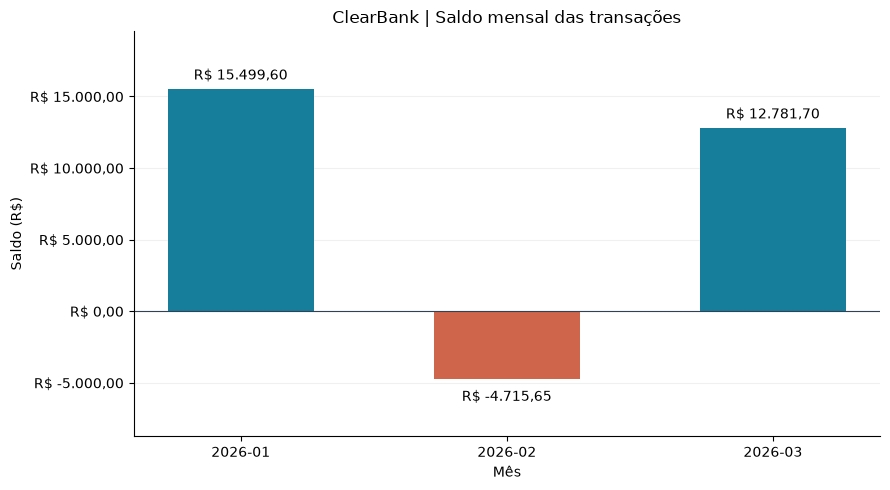

Gráfico salvo em grafico.png.


In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

meses = list(relatorio['resumo_mensal'])
saldos = [relatorio['resumo_mensal'][m]['saldo'] for m in meses]
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(meses, saldos, color=['#167d9a' if s >= 0 else '#cf654a' for s in saldos], width=0.55)
ax.axhline(0, color='#334155', linewidth=0.8)
ax.set(title='ClearBank | Saldo mensal das transações', xlabel='Mês', ylabel='Saldo (R$)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: moeda(valor)))
ax.grid(axis='y', alpha=0.18)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
for mes, saldo in zip(meses, saldos):
    ax.annotate(moeda(saldo), (mes, saldo), xytext=(0, 7 if saldo >= 0 else -16),
                textcoords='offset points', ha='center', fontsize=10)
ax.margins(y=0.2)
fig.tight_layout()
fig.savefig('grafico.png', dpi=160, bbox_inches='tight')
plt.show()
print('Gráfico salvo em grafico.png.')

## Leitura dos resultados
Janeiro apresenta saldo positivo de **R$ 15.499,60**. Fevereiro tem saldo de **−R$ 4.715,65**, influenciado pelo débito de R$ 11.000,00. Março encerra com **R$ 12.781,70**. Esses valores representam o fluxo das transações do arquivo, não o saldo bancário dos clientes, pois não há saldo inicial.

Os IDs 3 e 7 acionam o alerta por valor. O ID 12, de exatamente R$ 10.000,00, não aciona. O descarte de 11 das 26 linhas mostra por que a validação precisa anteceder a análise; essa proporção foi propositalmente elevada na base de teste.

A comparação com pandas verifica as sete métricas mensais; ambas as versões compartilham a regra de validação, enquanto a leitura e o agrupamento são implementados separadamente.
